# Sheet 11: Classification of latent variables

demonstrated on the UCI spam vs. ham dataset

In [1]:
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import requests
import zipfile
import io
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer, AutoModel
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

In [2]:
# --- 1. SETUP & DATA LOADING ---
#MODEL_NAME = "prajjwal1/bert-mini"
MODEL_NAME = "prajjwal1/bert-medium" # (165MB, 512 dim)
BATCH_SIZE = 16
LR = 0.001

print(f">>> Loading Dataset...")
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip"

# Download and extract specific file from ZIP in memory
r = requests.get(url)
with zipfile.ZipFile(io.BytesIO(r.content)) as z:
    # Explicitly open the data file, ignoring 'readme'
    with z.open('SMSSpamCollection') as f:
        df = pd.read_csv(f, sep='\t', names=["label", "text"], header=None)

df['label'] = df['label'].map({'ham': 0, 'spam': 1})
print(f"Loaded {len(df)} rows. Spam count: {df['label'].sum()}")

print(f">>> Loading Model: {MODEL_NAME}...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
bert_model = AutoModel.from_pretrained(MODEL_NAME)
bert_model.eval()  # Freeze BERT

>>> Loading Dataset...
Loaded 5572 rows. Spam count: 747
>>> Loading Model: prajjwal1/bert-medium...


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 512, padding_idx=0)
    (position_embeddings): Embedding(512, 512)
    (token_type_embeddings): Embedding(2, 512)
    (LayerNorm): LayerNorm((512,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-7): 8 x BertLayer(
        (attention): BertAttention(
          (self): BertSdpaSelfAttention(
            (query): Linear(in_features=512, out_features=512, bias=True)
            (key): Linear(in_features=512, out_features=512, bias=True)
            (value): Linear(in_features=512, out_features=512, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=512, out_features=512, bias=True)
            (LayerNorm): LayerNorm((512,), eps=1e-12, elementwise_affine=True)
            (dropout): Dropout(p=0.1, inplace=False)


In [3]:
# --- 2. FEATURE EXTRACTION (BERT) ---
def get_embeddings(text_list):
    inputs = tokenizer(text_list, padding=True, truncation=True, 
                       max_length=64, return_tensors="pt")
    with torch.no_grad():
        outputs = bert_model(**inputs)
    return outputs.last_hidden_state[:, 0, :]

print(">>> Generating Latent Representations...")
embeddings = []
# Batch processing
for i in range(0, len(df), 100):
    batch = df['text'].iloc[i : i+100].tolist()
    embeddings.append(get_embeddings(batch))

X = torch.cat(embeddings) 
y = torch.tensor(df['label'].values, dtype=torch.float32).unsqueeze(1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)

>>> Generating Latent Representations...


In [4]:
# --- 3. CLASSIFICATION (MLP) ---
class SimpleMLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)

clf = SimpleMLP(input_dim=X.shape[1])
optimizer = optim.Adam(clf.parameters(), lr=LR)
criterion = nn.BCELoss()

print(f">>> Training MLP...")
for epoch in range(5):
    epoch_loss = 0
    for bx, by in train_loader:
        optimizer.zero_grad()
        loss = criterion(clf(bx), by)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    print(f"Epoch {epoch+1}: Loss = {epoch_loss/len(train_loader):.4f}")

>>> Training MLP...
Epoch 1: Loss = 0.0777
Epoch 2: Loss = 0.0350
Epoch 3: Loss = 0.0318
Epoch 4: Loss = 0.0243
Epoch 5: Loss = 0.0209


In [5]:
# --- 4. EVALUATION ---
clf.eval()
with torch.no_grad():
    y_pred = (clf(X_test) > 0.5).float()
    acc = (y_pred.eq(y_test).sum() / float(y_test.shape[0])).item()
print(f"\n>>> Final Test Accuracy: {acc*100:.2f}%")


>>> Final Test Accuracy: 98.48%


>>> Visualizing...


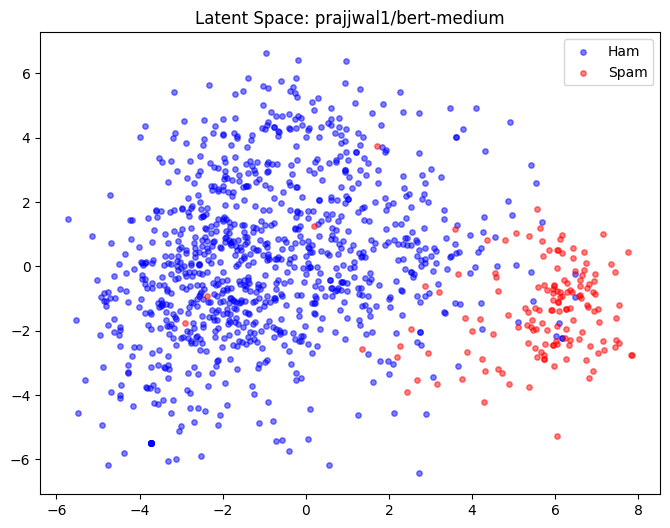

In [6]:
# --- 5. VISUALIZATION ---
print(">>> Visualizing...")
pca = PCA(n_components=2)
X_reduced = pca.fit_transform(X_test.numpy())
labels = y_test.flatten().numpy()

plt.figure(figsize=(8, 6))
plt.scatter(X_reduced[labels==0, 0], X_reduced[labels==0, 1], c='blue', label='Ham', alpha=0.5, s=15)
plt.scatter(X_reduced[labels==1, 0], X_reduced[labels==1, 1], c='red', label='Spam', alpha=0.5, s=15)
plt.legend()
plt.title(f"Latent Space: {MODEL_NAME}")
plt.show()

## Dreaming

In [7]:
import torch.nn.functional as F

def generate_spam_trigger(seq_length=5, steps=500, lr=0.1):
    print(f">>> Dreaming of a {seq_length}-word input that triggers SPAM...")

    # 1. Start with random vectors that look roughly like normal word embeddings
    # We use the model's own embedding stats to scale the noise correctly
    vocab_matrix = bert_model.embeddings.word_embeddings.weight.detach()
    mean = vocab_matrix.mean()
    std = vocab_matrix.std()
    
    # Create our "Soft Words" - a trainable tensor of shape (1, seq_length, dim)
    # This represents 5 placeholder words that we will optimize
    soft_embeds = torch.normal(mean, std, size=(1, seq_length, vocab_matrix.shape[1]), 
                               device=X.device, requires_grad=True)
    
    optimizer = torch.optim.Adam([soft_embeds], lr=lr)
    
    # 2. Optimization Loop
    for i in range(steps):
        optimizer.zero_grad()
        
        # KEY TRICK: We bypass the Tokenizer! 
        # We feed our 'soft_embeds' directly into BERT using 'inputs_embeds'
        outputs = bert_model(inputs_embeds=soft_embeds)
        
        # Get the [CLS] token (first position) representation
        cls_vector = outputs.last_hidden_state[:, 0, :]
        
        # Feed to MLP Classifier
        spam_prob = clf(cls_vector)
        
        # We want probability -> 1.0, so we minimize (1 - prob)
        loss = 1.0 - spam_prob
        loss.backward()
        optimizer.step()
        
        if i % 100 == 0:
            print(f"Step {i}: Current Spam Probability: {spam_prob.item():.4f}")

    print(f"Final Spam Probability: {spam_prob.item():.4f}")
    return soft_embeds.detach()

def decode_soft_embeds(soft_embeds):
    """
    Finds the real English words closest to our optimized 'Soft Words'.
    """
    vocab_matrix = bert_model.embeddings.word_embeddings.weight.detach()
    
    # Compute distances between our 5 soft words and ALL 30k vocab words
    # We use Cosine Similarity
    soft_embeds = F.normalize(soft_embeds.squeeze(), p=2, dim=1)
    vocab_matrix = F.normalize(vocab_matrix, p=2, dim=1)
    
    # Matrix Multiplication to get similarity scores
    similarity = torch.mm(soft_embeds, vocab_matrix.t())
    
    print("\n>>> The Generated 'Spam' Sequence:")
    decoded_sentence = []
    
    # For each position in our sequence, pick the best word
    for i in range(similarity.shape[0]):
        # Get index of the most similar word
        best_idx = torch.argmax(similarity[i]).item()
        word = tokenizer.decode([best_idx])
        decoded_sentence.append(word)
        print(f"Pos {i+1}: '{word}' (Confidence: {similarity[i].max().item():.2f})")
        
    print(f"\nFinal Sentence: \"{' '.join(decoded_sentence)}\"")

# --- RUN IT ---
# We ask for a 3-word sequence that causes maximum Spam activation
dream_embeds = generate_spam_trigger(seq_length=3)
decode_soft_embeds(dream_embeds)

>>> Dreaming of a 3-word input that triggers SPAM...
Step 0: Current Spam Probability: 0.0007
Step 100: Current Spam Probability: 1.0000
Step 200: Current Spam Probability: 1.0000
Step 300: Current Spam Probability: 1.0000
Step 400: Current Spam Probability: 1.0000
Final Spam Probability: 1.0000

>>> The Generated 'Spam' Sequence:
Pos 1: 'sending' (Confidence: 0.18)
Pos 2: 'barrett' (Confidence: 0.21)
Pos 3: 'leonardo' (Confidence: 0.18)

Final Sentence: "sending barrett leonardo"


## Saliency

In [8]:
def explain_prediction(text):
    inputs = tokenizer(text, return_tensors="pt", padding=True)
    
    # We need access to the embedding layer output to calculate gradients relative to it
    embeddings = bert_model.embeddings(inputs['input_ids'])
    embeddings.retain_grad() # Tell PyTorch to keep gradients for this tensor
    
    # Forward pass through the rest of BERT manually
    # (Note: This is simplified; BERT has more steps, but this works for a rough demo)
    encoder_output = bert_model.encoder(embeddings).last_hidden_state[:, 0, :]
    prediction = clf(encoder_output)
    
    # Backprop
    prediction.backward()
    
    # The gradient tells us how much 'prediction' changes if we change the word vector
    # We take the magnitude of the gradient (L2 norm) for each token
    grad_magnitude = embeddings.grad.norm(dim=2).squeeze()
    
    print(f"\n>>> Saliency Map for: '{text}'")
    tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
    for token, score in zip(tokens, grad_magnitude):
        if token not in ['[CLS]', '[SEP]', '[PAD]']:
            print(f"{token}: {score:.4f}")

# Usage
explain_prediction("armada bright 512")


>>> Saliency Map for: 'armada bright 512'
armada: 0.3088
bright: 0.2635
512: 0.4037


In [9]:
import ipywidgets as widgets
from IPython.display import display, HTML
import torch.nn.functional as F

# --- 1. Saliency Function with HTML Output ---
def get_saliency(text):
    """
    Calculates gradient-based importance of each word.
    Returns: (list of tokens, list of scores)
    """
    if not text.strip(): return [], []
    
    # Setup inputs
    inputs = tokenizer(text, return_tensors="pt", padding=True, truncation=True)
    input_ids = inputs['input_ids']
    
    # 1. Get Embeddings manually so we can track gradients on them
    # Note: This accesses internal BERT layers. Works for 'bert-mini'.
    embedding_layer = bert_model.embeddings.word_embeddings
    inputs_embeds = embedding_layer(input_ids)
    inputs_embeds.retain_grad() # Crucial: Allows us to see gradients here
    
    # 2. Forward Pass using inputs_embeds instead of input_ids
    # We must explicitly pass attention_mask so BERT knows what is padding
    outputs = bert_model(inputs_embeds=inputs_embeds, attention_mask=inputs['attention_mask'])
    cls_token = outputs.last_hidden_state[:, 0, :]
    
    # 3. Classify and Backpropagate
    prediction = clf(cls_token)
    prediction.backward()
    
    # 4. Calculate Importance (Gradient Magnitude)
    # Norm of the gradient vector for each token
    grad = inputs_embeds.grad[0].norm(dim=1).detach().numpy()
    
    # Normalize scores to 0-1 range for coloring
    grad = (grad - grad.min()) / (grad.max() - grad.min() + 1e-9)
    
    tokens = tokenizer.convert_ids_to_tokens(input_ids[0])
    return tokens, grad, prediction.item()

def render_html(tokens, scores, spam_prob):
    """Generates HTML with words highlighted by importance."""
    html_str = f"<h3>Spam Probability: {spam_prob:.1%}</h3><div style='font-size:16px; line-height: 1.6;'>"
    
    for token, score in zip(tokens, scores):
        if token in ['[CLS]', '[SEP]', '[PAD]']: continue
        
        # Clean up BERT tokens (remove '##' subword artifacts)
        display_text = token.replace("##", "")
        
        # Color: White -> Red based on score
        alpha = score * 0.8  # Max opacity 0.8 so text remains readable
        bg_color = f"rgba(255, 0, 0, {alpha})"
        
        html_str += f"<span style='background-color:{bg_color}; padding: 2px 4px; margin: 0 2px; border-radius: 4px;'>{display_text}</span>"
        
    html_str += "</div>"
    return html_str

# --- 2. Build the Widget ---

# Input Text Area
text_area = widgets.Textarea(
    value='armada bright 512',
    placeholder='Type something...',
    description='Message:',
    layout=widgets.Layout(width='90%', height='80px')
)

# Output Area (where the result appears)
out = widgets.Output()

def on_text_change(change):
    new_text = change['new']
    with out:
        out.clear_output(wait=True)
        # Re-run explanation
        try:
            tokens, scores, prob = get_saliency(new_text)
            display(HTML(render_html(tokens, scores, prob)))
        except Exception as e:
            print(f"Waiting for valid input... ({e})")

# Link the function to the text area
text_area.observe(on_text_change, names='value')

# Trigger once to show initial state
on_text_change({'new': text_area.value})

# Display Widgets
display(widgets.VBox([text_area, out]))